# EXO1:

In [9]:
sentences = [
    "The movie was absolutely fantastic and a masterpiece.",
    "I hated the film, it was far too long.",
    "A brilliant performance by the lead actor.",
    "Not my favorite, but the cinematography was stunning.",
    "What an incredible experience to watch this in theaters!"
]

In [10]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Initialize the Tokenizer with a vocabulary size of 50
tokenizer = Tokenizer(num_words=50, oov_token="<OOV>")
tokenizer.fit_on_texts(sentences)

# Convert sentences to sequences of integers
sequences = tokenizer.texts_to_sequences(sentences)
word_index = tokenizer.word_index

In [11]:
# Experimenting with different configurations
pre_pad = pad_sequences(sequences, maxlen=10, padding='pre')
post_pad = pad_sequences(sequences, maxlen=10, padding='post')

# Using a shorter maxlen to demonstrate truncation
pre_trunc = pad_sequences(sequences, maxlen=5, truncating='pre')
post_trunc = pad_sequences(sequences, maxlen=5, truncating='post')

In [12]:
print(" PAD ")
print(pre_pad)
print("-------------------------------")
print(post_pad)
print("-------------------------------")
print("-------------------------------")
print
print(" Trunc ")
print(pre_trunc)
print("-------------------------------")
print(post_trunc)

 PAD 
[[ 0  0  2  5  3  6  7  8  4  9]
 [ 0 10 11  2 12 13  3 14 15 16]
 [ 0  0  0  4 17 18 19  2 20 21]
 [ 0  0 22 23 24 25  2 26  3 27]
 [ 0 28 29 30 31 32 33 34 35 36]]
-------------------------------
[[ 2  5  3  6  7  8  4  9  0  0]
 [10 11  2 12 13  3 14 15 16  0]
 [ 4 17 18 19  2 20 21  0  0  0]
 [22 23 24 25  2 26  3 27  0  0]
 [28 29 30 31 32 33 34 35 36  0]]
-------------------------------
-------------------------------
 Trunc 
[[ 6  7  8  4  9]
 [13  3 14 15 16]
 [18 19  2 20 21]
 [25  2 26  3 27]
 [32 33 34 35 36]]
-------------------------------
[[ 2  5  3  6  7]
 [10 11  2 12 13]
 [ 4 17 18 19  2]
 [22 23 24 25  2]
 [28 29 30 31 32]]


| Feature | pre | post |
| -------- | -------- | -------- |
| Padding | "[0, 0, 1, 2, 3]" | "[1, 2, 3, 0, 0]" |
| Truncation | Keeps the end of the sentence | Keeps the start of the sentence |

# EXO2:

17464789/17464789 [==============================] - 2s 0us/step


2026-05-01 21:27:57.637145: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-05-01 21:27:57.830770: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-05-01 21:27:57.830979: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-05-01 21:27:57.831560: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 200, 32)           320000    
                                                                 
 simple_rnn (SimpleRNN)      (None, 32)                2080      
                                                                 
 dense (Dense)               (None, 1)                 33        
                                                                 
Total params: 322,113
Trainable params: 322,113
Non-trainable params: 0
_________________________________________________________________
Epoch 1/5
157/157 [==============================] - 29s 174ms/step - loss: 0.5192 - accuracy: 0.7375 - val_loss: 0.3942 - val_accuracy: 0.8348
Epoch 2/5
157/157 [==============================] - 26s 165ms/step - loss: 0.3413 - accuracy: 0.8566 - val_loss: 0.3576 - val_accuracy: 0.8524
Epoch 3/5
157/157 [=======

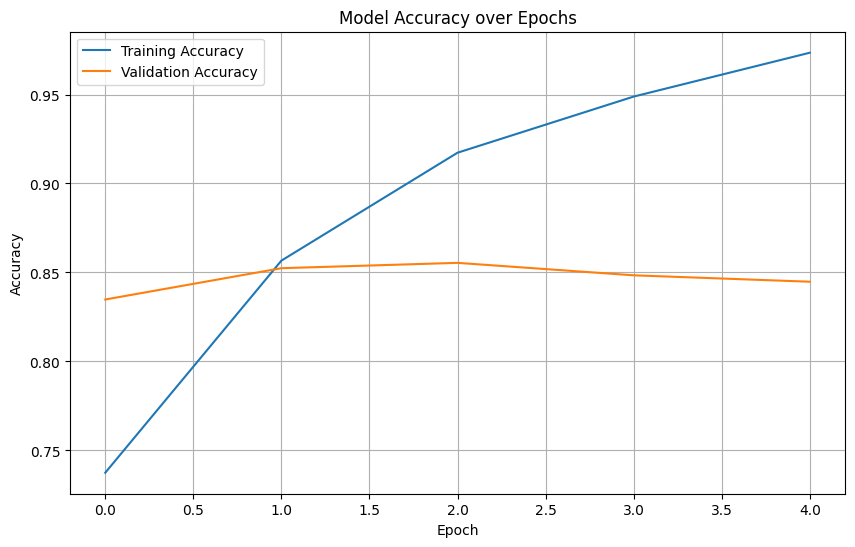

In [ ]:
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
import matplotlib.pyplot as plt

# 1. Load the IMDB dataset (Top 10,000 words)
num_words = 10000
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=num_words)

# 2. Pad the sequences to a fixed length of 200
maxlen = 200
x_train = pad_sequences(x_train, maxlen=maxlen)
x_test = pad_sequences(x_test, maxlen=maxlen)

# 3. Build the SimpleRNN model
model = Sequential([
    # input_dim=10000, output_dim=32, input_length=200
    Embedding(input_dim=num_words, output_dim=32, input_length=maxlen),
    # SimpleRNN layer with 32 units
    SimpleRNN(32),
    # Dense layer with 1 unit and sigmoid for binary classification
    Dense(1, activation='sigmoid')
])

# 4. Compile with adam and binary_crossentropy
model.compile(optimizer='adam', 
              loss='binary_crossentropy', 
              metrics=['accuracy'])

# Print model summary to verify architecture
model.summary()

# 5. Train for 5 epochs and evaluate
history = model.fit(x_train, y_train, 
                    epochs=5, 
                    batch_size=128, 
                    validation_split=0.2)

test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"\nTest Accuracy: {test_acc:.4f}")

# 6. Plot training and validation accuracy
plt.figure(figsize=(10, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

the model overfitted, this could be fixed by giving the RNN less units, implementing early stop or adding dropout.

# EXO3:


Training Model with SimpleRNN...
Epoch 1/5
157/157 [==============================] - 28s 173ms/step - loss: 0.6642 - accuracy: 0.5789 - val_loss: 0.5069 - val_accuracy: 0.7812
Epoch 2/5
157/157 [==============================] - 27s 169ms/step - loss: 0.4482 - accuracy: 0.8024 - val_loss: 0.4997 - val_accuracy: 0.7436
Epoch 3/5
157/157 [==============================] - 30s 192ms/step - loss: 0.3066 - accuracy: 0.8763 - val_loss: 0.4384 - val_accuracy: 0.8052
Epoch 4/5
157/157 [==============================] - 35s 226ms/step - loss: 0.1619 - accuracy: 0.9447 - val_loss: 0.4567 - val_accuracy: 0.8096
Epoch 5/5
157/157 [==============================] - 31s 199ms/step - loss: 0.0719 - accuracy: 0.9815 - val_loss: 0.4800 - val_accuracy: 0.8306

Training Model with LSTM...
Epoch 1/5


2026-05-01 21:39:31.753753: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8100


157/157 [==============================] - 8s 31ms/step - loss: 0.4884 - accuracy: 0.7559 - val_loss: 0.3299 - val_accuracy: 0.8626
Epoch 2/5
157/157 [==============================] - 3s 20ms/step - loss: 0.2487 - accuracy: 0.9043 - val_loss: 0.2920 - val_accuracy: 0.8804
Epoch 3/5
157/157 [==============================] - 4s 24ms/step - loss: 0.1867 - accuracy: 0.9327 - val_loss: 0.3343 - val_accuracy: 0.8632
Epoch 4/5
157/157 [==============================] - 3s 21ms/step - loss: 0.1426 - accuracy: 0.9507 - val_loss: 0.3391 - val_accuracy: 0.8742
Epoch 5/5
157/157 [==============================] - 3s 20ms/step - loss: 0.1074 - accuracy: 0.9668 - val_loss: 0.3663 - val_accuracy: 0.8728

Training Model with GRU...
Epoch 1/5
157/157 [==============================] - 7s 35ms/step - loss: 0.5319 - accuracy: 0.7095 - val_loss: 0.3493 - val_accuracy: 0.8534
Epoch 2/5
157/157 [==============================] - 5s 30ms/step - loss: 0.2666 - accuracy: 0.8940 - val_loss: 0.3198 - val_accur

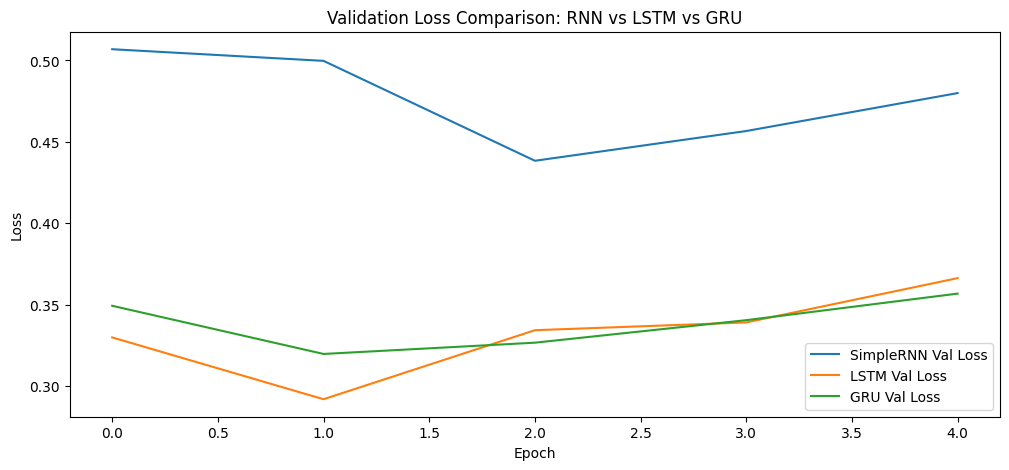

In [7]:
import time
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense
import matplotlib.pyplot as plt

# Data Setup (same as image_2db7dc.jpg)
num_words = 10000
maxlen = 200
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=num_words)
x_train = pad_sequences(x_train, maxlen=maxlen)
x_test = pad_sequences(x_test, maxlen=maxlen)

# Model definitions
cell_types = [SimpleRNN, LSTM, GRU]
results = {}

plt.figure(figsize=(12, 5))

for cell in cell_types:
    name = cell.__name__
    print(f"\nTraining Model with {name}...")
    
    model = Sequential([
        Embedding(input_dim=num_words, output_dim=32, input_length=maxlen),
        cell(32),
        Dense(1, activation='sigmoid')
    ])
    
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    
    # Track training time
    start_time = time.time()
    history = model.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.2, verbose=1)
    end_time = time.time()
    
    # Evaluate
    _, test_acc = model.evaluate(x_test, y_test, verbose=0)
    
    results[name] = {
        'accuracy': test_acc,
        'time': end_time - start_time,
        'history': history.history
    }
    
    # Plotting loss curves
    plt.plot(history.history['val_loss'], label=f'{name} Val Loss')

# Final Comparison Output
print("\n--- Final Comparison ---")
for name, data in results.items():
    print(f"{name}: Test Accuracy = {data['accuracy']:.4f}, Total Time = {data['time']:.2f}s")

plt.title('Validation Loss Comparison: RNN vs LSTM vs GRU')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

gru and lstm converged and trained faster bc the gates allowed them to learn meaningful relationships in the data without going through useless multiplications by low values

# EXO4:

Testing Embedding Dimension: 16...
Testing Embedding Dimension: 32...
Testing Embedding Dimension: 64...
Testing Embedding Dimension: 128...


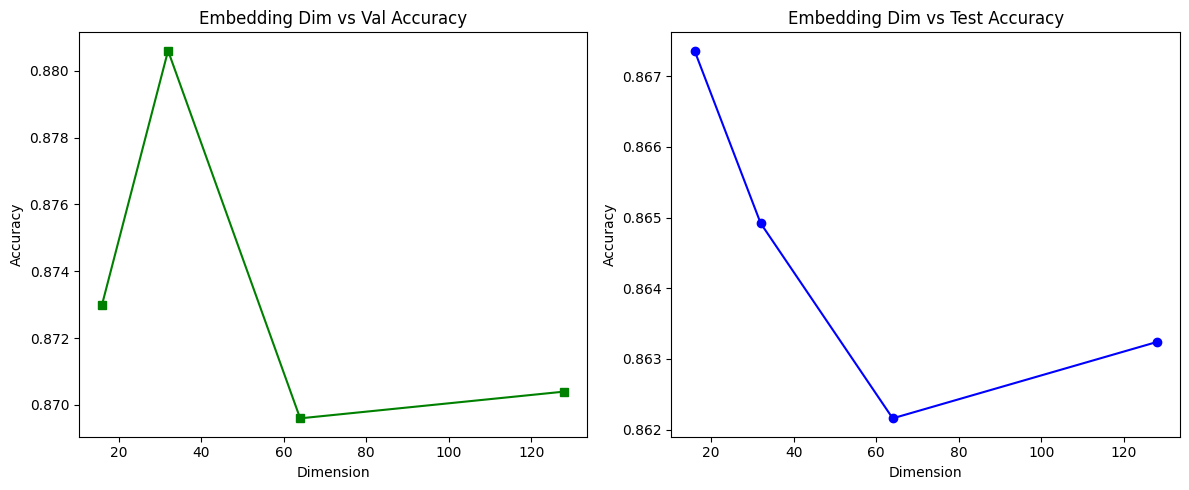

In [19]:
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
import matplotlib.pyplot as plt

# Dataset Setup
num_words = 10000
maxlen = 200
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=num_words)

# FIXED: Both train and test must be padded to the same maxlen
x_train = pad_sequences(x_train, maxlen=maxlen)
x_test = pad_sequences(x_test, maxlen=maxlen)

embedding_dims = [16, 32, 64, 128]
val_accuracies = []
test_accuracies = []

for dim in embedding_dims:
    print(f"Testing Embedding Dimension: {dim}...")
    model = Sequential([
        Embedding(input_dim=num_words, output_dim=dim, input_length=maxlen),
        LSTM(32),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    
    # Train
    history = model.fit(x_train, y_train, epochs=3, batch_size=128, validation_split=0.2, verbose=0)
    
    # Record results
    val_accuracies.append(history.history['val_accuracy'][-1])
    _, test_acc = model.evaluate(x_test, y_test, verbose=0)
    test_accuracies.append(test_acc)

# Plotting
plt.figure(figsize=(12, 5))

# Validation Plot
plt.subplot(1, 2, 1)
plt.plot(embedding_dims, val_accuracies, marker='s', color='green')
plt.title('Embedding Dim vs Val Accuracy')
plt.xlabel('Dimension')
plt.ylabel('Accuracy')

# Test Plot
plt.subplot(1, 2, 2)
plt.plot(embedding_dims, test_accuracies, marker='o', color='blue')
plt.title('Embedding Dim vs Test Accuracy')
plt.xlabel('Dimension')
plt.ylabel('Accuracy')

plt.tight_layout()
plt.show()

higher embeddding dimension lead to similar test accuracy as lower dims but more overfitting since the model just memorized the data,the difference is negligible however (only 1%)